In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error

## 1. Carregar e preparar o dataset

In [2]:
df = pd.read_csv("../dados/mecaniqa_dataset.csv", parse_dates=["Data"])
df = df.sort_values("Data").set_index("Data")

dados = df.copy()
dados["Lag_1"] = dados["Trocas_Oleo"].shift(1)
dados["Lag_7"] = dados["Trocas_Oleo"].shift(7)
dados["Media_7"] = dados["Trocas_Oleo"].shift(1).rolling(7).mean()
dados["Dia_Semana"] = dados.index.dayofweek

colunas = ["Lag_1", "Lag_7", "Media_7", "Dia_Semana"]
dados = dados.dropna(subset=colunas + ["Trocas_Oleo"])

X = dados[colunas]
y = dados["Trocas_Oleo"]

print("Registros válidos:", len(dados))
print("Atributos usados:", colunas)
display(dados.head())

Registros válidos: 711
Atributos usados: ['Lag_1', 'Lag_7', 'Media_7', 'Dia_Semana']


,Trocas_Oleo,Manutencao_Motor,Lag_1,Lag_7,Media_7,Dia_Semana
Data,,,,,,
2024-01-08,13.0,8.0,31.0,11.0,18.285714,0
2024-01-09,10.0,6.0,13.0,9.0,18.571429,1
2024-01-10,13.0,1.0,10.0,12.0,18.714286,2
2024-01-11,10.0,1.0,13.0,15.0,18.857143,3
2024-01-12,25.0,8.0,10.0,25.0,18.142857,4


## 2. Separar treino e teste em ordem cronológica

In [3]:
corte = int(len(dados) * 0.8)

X_treino, X_teste = X.iloc[:corte], X.iloc[corte:]
y_treino, y_teste = y.iloc[:corte], y.iloc[corte:]

assert X_treino.index.max() < X_teste.index.min(), "Os períodos de treino e teste se sobrepõem."

print("Treino:", len(X_treino), "registros |", X_treino.index.min().date(), "a", X_treino.index.max().date())
print("Teste:", len(X_teste), "registros |", X_teste.index.min().date(), "a", X_teste.index.max().date())

Treino: 568 registros | 2024-01-08 a 2025-08-10
Teste: 143 registros | 2025-08-11 a 2025-12-31


## 3. Baseline e modelo ML inicial

In [4]:
previsao_baseline = dados.loc[X_teste.index, "Media_7"].to_numpy()

modelo_inicial = RandomForestRegressor(random_state=42)
modelo_inicial.fit(X_treino, y_treino)
previsao_inicial = modelo_inicial.predict(X_teste)

print("Previsões do baseline e do modelo inicial geradas.")

Previsões do baseline e do modelo inicial geradas.


## 4. Treinar o Random Forest tunado com Grid Search

In [5]:
parametros = {
    "n_estimators": [50, 100, 200],
    "max_depth": [5, 10, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4]
}

tscv = TimeSeriesSplit(n_splits=5)
grid = GridSearchCV(
    RandomForestRegressor(random_state=42),
    param_grid=parametros,
    scoring="neg_mean_absolute_error",
    cv=tscv,
    n_jobs=-1
)

grid.fit(X_treino, y_treino)
modelo_tunado = grid.best_estimator_
previsao_tunada = modelo_tunado.predict(X_teste)

print("Melhores hiperparâmetros:", grid.best_params_)
print(f"MAE médio na validação temporal (treino): {-grid.best_score_:.2f}")

Melhores hiperparâmetros: {'max_depth': 5, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 100}
MAE médio na validação temporal (treino): 4.50


## 5. Motor de métricas: MAE, RMSE e MAPE

In [6]:
def calcular_metricas(real, previsto):
    real = np.asarray(real, dtype=float)
    previsto = np.asarray(previsto, dtype=float)
    mae = mean_absolute_error(real, previsto)
    rmse = np.sqrt(mean_squared_error(real, previsto))
    validos = real != 0
    mape = mean_absolute_percentage_error(real[validos], previsto[validos]) * 100 if validos.any() else np.nan
    return {"MAE": mae, "RMSE": rmse, "MAPE (%)": mape}

resultados = []
for nome, previsao in [
    ("Baseline Média 7", previsao_baseline),
    ("Random Forest Inicial", previsao_inicial),
    ("Random Forest Tunado", previsao_tunada)
]:
    resultados.append({"Modelo": nome, **calcular_metricas(y_teste, previsao)})

tabela_final = pd.DataFrame(resultados).set_index("Modelo")
display(tabela_final.round(2))

for metrica in ["MAE", "RMSE", "MAPE (%)"]:
    erro_baseline = tabela_final.loc["Baseline Média 7", metrica]
    erro_inicial = tabela_final.loc["Random Forest Inicial", metrica]
    erro_tunado = tabela_final.loc["Random Forest Tunado", metrica]
    vs_baseline = (erro_baseline - erro_tunado) / erro_baseline * 100 if erro_baseline != 0 else np.nan
    vs_inicial = (erro_inicial - erro_tunado) / erro_inicial * 100 if erro_inicial != 0 else np.nan
    print(f"{metrica}: melhoria do tunado vs. baseline = {vs_baseline:+.2f}% | vs. inicial = {vs_inicial:+.2f}%")

print("Atenção: porcentagens negativas significam piora de desempenho, não ganho.")

,MAE,RMSE,MAPE (%)
Modelo,,,
Baseline Média 7,7.39,8.16,31.13
Random Forest Inicial,3.04,3.98,13.64
Random Forest Tunado,3.16,4.27,14.37


MAE: melhoria do tunado vs. baseline = +57.21% | vs. inicial = -3.88%
RMSE: melhoria do tunado vs. baseline = +47.61% | vs. inicial = -7.29%
MAPE (%): melhoria do tunado vs. baseline = +53.82% | vs. inicial = -5.37%
Atenção: porcentagens negativas significam piora de desempenho, não ganho.


## 6. Gráfico comparativo final

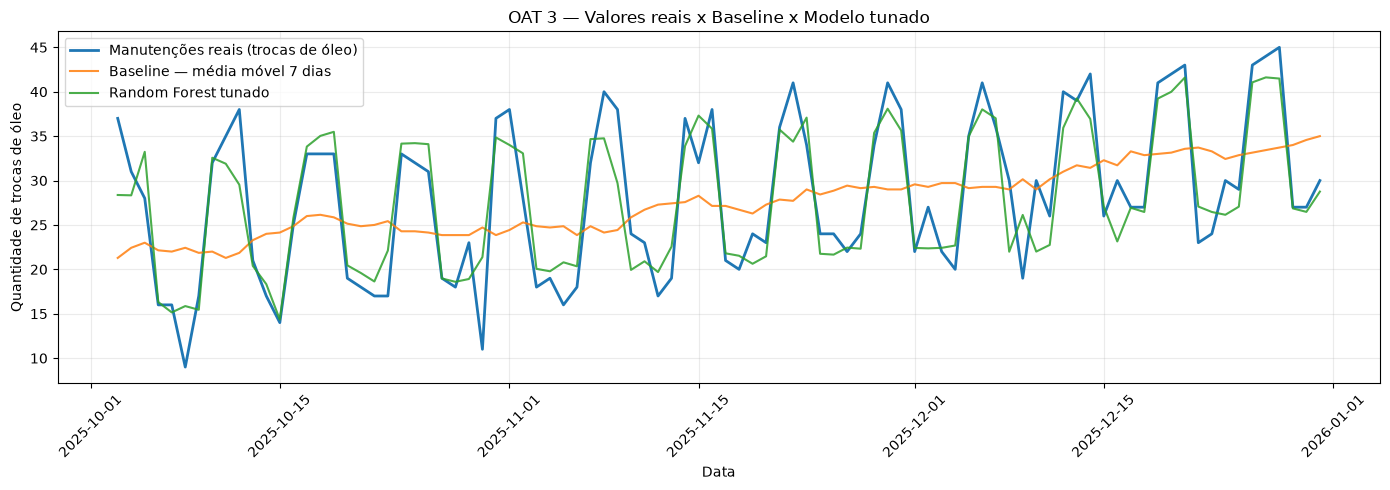

In [7]:
periodo = min(90, len(X_teste))
datas = X_teste.index[-periodo:]

plt.figure(figsize=(14, 5))
plt.plot(datas, y_teste.iloc[-periodo:], label="Manutenções reais (trocas de óleo)", linewidth=2)
plt.plot(datas, previsao_baseline[-periodo:], label="Baseline — média móvel 7 dias", alpha=0.85)
plt.plot(datas, previsao_tunada[-periodo:], label="Random Forest tunado", alpha=0.85)
plt.title("OAT 3 — Valores reais x Baseline x Modelo tunado")
plt.xlabel("Data")
plt.ylabel("Quantidade de trocas de óleo")
plt.legend()
plt.grid(alpha=0.25)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 7. Interpretação para a apresentação

- **MAE:** erro médio em número de trocas de óleo, geralmente o mais fácil de explicar ao dono da oficina.
- **RMSE:** penaliza mais os dias em que o modelo erra por uma margem grande.
- **MAPE:** traduz o erro em percentual, calculado somente nos dias com valor real diferente de zero.

In [8]:
principal = "MAE"
mae_baseline = tabela_final.loc["Baseline Média 7", principal]
mae_inicial = tabela_final.loc["Random Forest Inicial", principal]
mae_tunado = tabela_final.loc["Random Forest Tunado", principal]

print("CONCLUSÃO DA EQUIPE — COMPARAÇÃO FINAL")
print(f"Baseline Média 7: MAE = {mae_baseline:.2f}")
print(f"Random Forest inicial: MAE = {mae_inicial:.2f}")
print(f"Random Forest tunado: MAE = {mae_tunado:.2f}")

if mae_tunado < mae_baseline:
    print("O modelo tunado superou o baseline no MAE do período de teste.")
elif mae_tunado > mae_baseline:
    print("O modelo tunado não superou o baseline no MAE do período de teste.")
else:
    print("O modelo tunado e o baseline empataram no MAE do período de teste.")

if mae_tunado < mae_inicial:
    print("A otimização reduziu o MAE em relação ao Random Forest inicial.")
elif mae_tunado > mae_inicial:
    print("A otimização não reduziu o MAE em relação ao Random Forest inicial.")
else:
    print("O modelo inicial e o tunado empataram no MAE.")

CONCLUSÃO DA EQUIPE — COMPARAÇÃO FINAL
Baseline Média 7: MAE = 7.39
Random Forest inicial: MAE = 3.04
Random Forest tunado: MAE = 3.16
O modelo tunado superou o baseline no MAE do período de teste.
A otimização não reduziu o MAE em relação ao Random Forest inicial.
